# 🤖 PENGEMBANGAN MODEL CHATBOT PEMANDU BELAJAR SOKRATIK (PyJourney)
### Berbasis Dense Semantic Embeddings (Sentence-Transformers)
---
**Program Studi:** S-1 Teknik Informatika  
**Fakultas:** Teknik dan Ilmu Komputer (FTIK) - Universitas Nusantara PGRI Kediri  
**Peneliti / Penulis:** Ananda Salwa Pratama (NIM 2313020125)  
**Fokus Tugas Akhir (R&D):** *Asisten Belajar Interaktif Pemrograman Python Menggunakan Physical Socratic Companion (ESP32-S3) dan Validasi AST Sandbox*  

---
### 📌 Deskripsi & Tujuan Ilmiah
Notebook ini mengimplementasikan alur lengkap perancangan, pelatihan, dan evaluasi **Mesin Temu Kembali Informasi Semantik (Dense Semantic Retrieval Engine)** untuk Chatbot Pemandu Belajar Python.

Berbeda dengan chatbot generatif biasa yang sering memberikan kode instan (membuat mahasiswa malas dan mencontek), chatbot ini dirancang secara **Sokratik (Socratic Companion)**:
1. **Memahami Maksud Pertanyaan:** Mampu memahami variasi pertanyaan mahasiswa (bahasa santai, istilah awam, atau keluhan error).
2. **Menemukan Konsep yang Relevan:** Melakukan pemetaan semantik ke **5 Bab Resmi CPython** dan **15 Episode Konsep Mikro**.
3. **Memberikan Bimbingan Tanpa Membocorkan Solusi:** Menghasilkan petunjuk (*hint*), analogi konseptual, dan rujukan nomor bab/episode agar mahasiswa terdorong untuk memecahkan kode sendiri di Sandbox AST.

## 1. Setup Lingkungan & Import Dependensi
Pustaka yang digunakan dalam penelitian ini mencakup:
- `sentence-transformers` & `torch`: Arsitektur Transformer terlatih untuk ekstraksi vektor semantik kalimat (*dense embeddings*).
- `beautifulsoup4 (bs4)`: Ekstraksi dan sanitasi teks bersih dari markup HTML dokumen resmi.
- `scikit-learn`: Komputasi kesamaan kosinus (*Cosine Similarity*) dan pembagian dataset (*train-test split*).
- `pandas` & `numpy`: Manajemen struktur korpus tabular dan operasi aljabar matriks.
- `matplotlib`: Visualisasi grafik evaluasi metrik ilmiah (Top-K Accuracy & MRR).

In [1]:
import os
import re
import json
import random
from pathlib import Path
from bs4 import BeautifulSoup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sentence_transformers import SentenceTransformer, util
from sklearn.model_selection import train_test_split

# Tetapkan random seed agar hasil eksperimen dapat direproduksi (reproducible research)
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Konfigurasi direktori dataset
BASE_DIR = Path.cwd().parent
DATASET_DIR = BASE_DIR / "dataset"
CHAPTERS_DIR = DATASET_DIR / "generated" / "chapters"
CURRICULUM_PATH = DATASET_DIR / "curriculum.json"
OUTPUT_DIR = Path.cwd() / "output_artifacts"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"[STATUS] Komputasi berjalan pada perangkat: {device.upper()}")
print(f"[STATUS] Direktori Bab Materi: {CHAPTERS_DIR.resolve()}")
print(f"[STATUS] File Kurikulum: {CURRICULUM_PATH.resolve()} (Tersedia: {CURRICULUM_PATH.exists()})")

/media/pratama/Data1/Other/SELURUH FILE PERKULIAHAN/SKRIPSI/projek2/training-model/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[STATUS] Komputasi berjalan pada perangkat: CPU
[STATUS] Direktori Bab Materi: /media/pratama/Data1/Other/SELURUH FILE PERKULIAHAN/SKRIPSI/projek2/training-model/dataset/generated/chapters
[STATUS] File Kurikulum: /media/pratama/Data1/Other/SELURUH FILE PERKULIAHAN/SKRIPSI/projek2/training-model/dataset/curriculum.json (Tersedia: True)


## 2. Eksplorasi Korpus & Analisis Noise Teks HTML
Dataset materi berasal dari dokumentasi resmi CPython yang dikonversi dari reStructuredText melalui Sphinx JSON Builder. Di dalam properti `html` pada file JSON, terdapat elemen-elemen web seperti:
- `<a href="...">`: Tautan rujukan dokumentasi eksternal.
- `<code>`: Penanda sintaksis bahasa Python.
- `<em>`: Penekanan terminologi miring.

Mari kita inspeksi contoh teks mentah tersebut untuk melihat seberapa besar noise yang dihasilkan jika tidak dibersihkan.

In [2]:
# Membaca salah satu file materi untuk melihat contoh teks mentah
sample_file = CHAPTERS_DIR / "fungsi.json"
with open(sample_file, "r", encoding="utf-8") as f:
    sample_data = json.load(f)

# Ambil satu blok HTML yang memiliki tag link dan format markup
sample_raw_html = sample_data["groups"][0]["blocks"][33]["html"]
print("=== CONTOH TEKS MENTAH DARI DATASET JSON ===")
print(sample_raw_html)
print("=" * 50)

=== CONTOH TEKS MENTAH DARI DATASET JSON ===
Fungsi juga dapat dipanggil menggunakan <a href="https://docs.python.org/3.13/glossary.html#term-keyword-argument" rel="noopener noreferrer" target="_blank">argumen kata kunci (keyword arguments)</a>
dalam bentuk <code>kwarg=value</code>. Sebagai contoh, fungsi berikut:


## 3. Preprocessing Pipeline & Sanitasi Teks HTML
Untuk menghasilkan representasi vektor semantik berkualitas tinggi, teks mentah harus dibersihkan melalui tahapan preprocessing:
1. **Ekstraksi Teks Bersih (*Plain Text Extraction*)**: Menghilangkan markup `<a href>`, `<div>`, `<span>`, dll. menggunakan `BeautifulSoup` dengan pemisah spasi alami.
2. **Preservasi Entitas Kode**: Konten di dalam tag `<code>` dipertahankan teksnya (misal: `def`, `range()`, `list`) karena merepresentasikan entitas inti pemrograman.
3. **Penyelamatan Metadata URL**: Link rujukan resmi diekstrak ke dalam atribut terpisah (`source_links`) agar dapat disajikan sebagai referensi tambahan oleh chatbot.
4. **Normalisasi Whitespace & Entitas HTML**: Karakter entitas web seperti `&gt;`, `&lt;`, `&amp;` dinormalkan kembali ke representasi karakter aslinya (`>`, `<`, `&`).

In [3]:
def clean_html_content(raw_html: str) -> tuple[str, list[str]]:
    """
    Membersihkan teks HTML dokumentasi menjadi teks murni untuk input NLP,
    sekaligus mengekstraksi daftar URL rujukan jika tersedia.
    """
    if not raw_html or not isinstance(raw_html, str):
        return "", []

    soup = BeautifulSoup(raw_html, "html.parser")

    # 1. Kumpulkan tautan resmi dari tag <a href>
    links = []
    for a_tag in soup.find_all("a", href=True):
        href = a_tag.get("href", "").strip()
        if href and href.startswith("http"):
            links.append(href)

    # 2. Ambil teks murni dengan pemisah spasi
    clean_text = soup.get_text(separator=" ", strip=True)

    # 3. Normalisasi spasi dan karakter baris baru berlebih
    clean_text = re.sub(r'\s+', ' ', clean_text).strip()

    return clean_text, list(dict.fromkeys(links))

# Uji coba fungsi pembersih pada sampel HTML
cleaned_text, extracted_urls = clean_html_content(sample_raw_html)
print("=== HASIL SANITASI & PREPROCESSING NLP ===")
print("Teks Bersih    :", cleaned_text)
print("URL Referensi  :", extracted_urls)
print("=" * 50)

=== HASIL SANITASI & PREPROCESSING NLP ===
Teks Bersih    : Fungsi juga dapat dipanggil menggunakan argumen kata kunci (keyword arguments) dalam bentuk kwarg=value . Sebagai contoh, fungsi berikut:
URL Referensi  : ['https://docs.python.org/3.13/glossary.html#term-keyword-argument']


## 4. Ekstraksi Korpus & Concept-Level Chunking
Materi dari 5 file bab JSON diekstraksi dan dipecah menjadi unit-unit pengetahuan (*knowledge passages*).
Setiap unit pengetahuan memuat metadata hierarkis:
- `chapter_order`: Urutan Bab (1 - 5).
- `chapter_slug`: Slug pengenal Bab (misal: `variabel-dan-tipe-data`).
- `chapter_title`: Judul Bab.
- `episode_id`: ID Episode Duolingo yang menaungi konsep tersebut.
- `episode_title`: Judul Episode.
- `concept`: Konsep mikro yang dipelajari pada episode tersebut.
- `passage_text`: Konten teks penjelasan materi yang sudah bersih dari tag HTML.
- `source_urls`: Tautan ke dokumentasi resmi Python.

In [4]:
# Baca struktur kurikulum resmi
with open(CURRICULUM_PATH, "r", encoding="utf-8") as f:
    curriculum_meta = json.load(f)

curriculum_lookup = {ch["slug"]: ch for ch in curriculum_meta["chapters"]}

corpus_records = []
total_blocks_processed = 0

for chapter_file in sorted(CHAPTERS_DIR.glob("*.json")):
    slug = chapter_file.stem
    if slug not in curriculum_lookup:
        continue

    ch_info = curriculum_lookup[slug]
    order = ch_info["order"]
    ch_title = ch_info["title"]
    episodes = ch_info.get("episodes", [])

    with open(chapter_file, "r", encoding="utf-8") as f:
        ch_data = json.load(f)

    groups = ch_data.get("groups", [])
    num_episodes = max(1, len(episodes))

    # Lakukan ekstraksi blok-blok teks materi
    all_cleaned_blocks = []
    for g_idx, group in enumerate(groups):
        for b_idx, block in enumerate(group.get("blocks", [])):
            total_blocks_processed += 1
            raw_html = block.get("html", "")
            clean_t, urls = clean_html_content(raw_html)
            # Filter hanya blok yang memuat penjelasan substansial (> 30 karakter)
            if len(clean_t) >= 30 and not clean_t.startswith(">>> "):
                all_cleaned_blocks.append({"text": clean_t, "urls": urls})

    # Petakan blok-blok materi ke dalam 3 Episode proporsional per Bab
    chunk_size = max(1, len(all_cleaned_blocks) // num_episodes)
    for ep_idx, ep in enumerate(episodes):
        start_i = ep_idx * chunk_size
        end_i = (ep_idx + 1) * chunk_size if ep_idx < num_episodes - 1 else len(all_cleaned_blocks)
        ep_blocks = all_cleaned_blocks[start_i:end_i]

        for b_item in ep_blocks:
            corpus_records.append({
                "chapter_order": order,
                "chapter_slug": slug,
                "chapter_title": ch_title,
                "episode_id": ep["id"],
                "episode_title": ep["title"],
                "concept": ep["concept"],
                "passage_text": b_item["text"],
                "source_urls": b_item["urls"]
            })

df_corpus = pd.DataFrame(corpus_records)
print(f"[STATUS] Berhasil memproses {total_blocks_processed} blok teks mentah.")
print(f"[STATUS] Total Passage Korpus Pengetahuan Terekstraksi: {len(df_corpus)} dokumen.")
print("\nDistribusi Dokumen per Bab:")
print(df_corpus["chapter_title"].value_counts().to_string())

[STATUS] Berhasil memproses 476 blok teks mentah.
[STATUS] Total Passage Korpus Pengetahuan Terekstraksi: 303 dokumen.

Distribusi Dokumen per Bab:
chapter_title
Fungsi dengan def               92
Variabel & Tipe Data            66
List & Dictionary               63
Percabangan if / elif / else    44
Perulangan for & while          38


## 5. Dataset Pengujian Sintesis & Data Splitting
Untuk menguji kehandalan Chatbot dalam suasana riil mahasiswa (skenario pengujian Bab 4 Skripsi), kita menyusun sekumpulan pertanyaan nyata yang mencakup:
1. **Pertanyaan Sintaks Baku**: Pertanyaan langsung mengenai cara penulisan kode.
2. **Pertanyaan Santai / Informal**: Pertanyaan dengan istilah awam atau slang mahasiswa.
3. **Pertanyaan Berorientasi Masalah / Error**: Pertanyaan saat kode mahasiswa gagal atau menghasilkan luaran yang tidak diinginkan.

Dataset pertanyaan ini memiliki label kebenaran (*ground truth*) berupa Bab dan Episode target, kemudian dibagi menjadi **Train Set (70%)** dan **Test Set (30%)** dengan stratifikasi bab.

In [5]:
# Dataset 35 skenario pertanyaan mahasiswa yang mewakili 5 Bab
benchmark_queries = [
    # Bab 1: Variabel & Tipe Data
    {"query": "Bagaimana cara mengubah teks angka menjadi integer di python?", "target_slug": "variabel-dan-tipe-data", "target_ep": "ep-1-bilangan"},
    {"query": "Apa bedanya pembagian garing satu dengan garing dua di python?", "target_slug": "variabel-dan-tipe-data", "target_ep": "ep-1-bilangan"},
    {"query": "Gimana cara ngambil 3 huruf pertama dari sebuah string?", "target_slug": "variabel-dan-tipe-data", "target_ep": "ep-2-string"},
    {"query": "Fungsi apa yang dipakai untuk menghitung panjang karakter string?", "target_slug": "variabel-dan-tipe-data", "target_ep": "ep-2-string"},
    {"query": "Kenapa string kosong atau angka 0 bernilai False saat dicek if?", "target_slug": "variabel-dan-tipe-data", "target_ep": "ep-3-boolean"},
    {"query": "Gimana cara menuliskan tipe data boolean True dan False yang benar?", "target_slug": "variabel-dan-tipe-data", "target_ep": "ep-3-boolean"},
    {"query": "Cara ngitung sisa bagi modulo operatornya apa ya bro?", "target_slug": "variabel-dan-tipe-data", "target_ep": "ep-1-bilangan"},

    # Bab 2: Percabangan
    {"query": "Kenapa ada error IndentationError saat nulis logika if?", "target_slug": "percabangan", "target_ep": "ep-1-if-dasar"},
    {"query": "Gimana cara membuat keputusan dasar if di python?", "target_slug": "percabangan", "target_ep": "ep-1-if-dasar"},
    {"query": "Bagaimana struktur percabangan yang memiliki lebih dari dua kondisi?", "target_slug": "percabangan", "target_ep": "ep-2-if-elif-else"},
    {"query": "Kapan kita harus menggunakan elif dibanding if baru?", "target_slug": "percabangan", "target_ep": "ep-2-if-elif-else"},
    {"query": "Apa kegunaan kata kunci pass di dalam blok percabangan?", "target_slug": "percabangan", "target_ep": "ep-3-kondisional"},
    {"query": "Cara nulis percabangan ringkas dalam satu baris ternary operator gimana?", "target_slug": "percabangan", "target_ep": "ep-3-kondisional"},
    {"query": "Biar kondisi dicek dua-duanya harus benar pakai operator logika apa?", "target_slug": "percabangan", "target_ep": "ep-2-if-elif-else"},

    # Bab 3: Perulangan
    {"query": "Bagaimana cara mengulang perulangan angka dari 0 sampai 10?", "target_slug": "perulangan", "target_ep": "ep-1-for-range"},
    {"query": "Gimana cara pakai fungsi range dengan kelipatan angka tertentu?", "target_slug": "perulangan", "target_ep": "ep-1-for-range"},
    {"query": "Kapan sebaiknya menggunakan loop while dibanding perulangan for?", "target_slug": "perulangan", "target_ep": "ep-2-while"},
    {"query": "Program saya macet tidak mau berhenti pas perulangan while kenapa ya?", "target_slug": "perulangan", "target_ep": "ep-2-while"},
    {"query": "Cara menghentikan paksa perulangan saat kondisi tertentu tercapai?", "target_slug": "perulangan", "target_ep": "ep-3-break-continue"},
    {"query": "Apa bedanya perintah break dan continue dalam looping?", "target_slug": "perulangan", "target_ep": "ep-3-break-continue"},
    {"query": "Apakah di python perulangan for bisa punya klausa else di ujungnya?", "target_slug": "perulangan", "target_ep": "ep-3-break-continue"},

    # Bab 4: Fungsi
    {"query": "Bagaimana cara membuat fungsi sendiri dengan kata kunci def?", "target_slug": "fungsi", "target_ep": "ep-1-def-docstring"},
    {"query": "Apa fungsi docstring tanda kutip tiga di bawah nama fungsi?", "target_slug": "fungsi", "target_ep": "ep-1-def-docstring"},
    {"query": "Gimana cara membuat parameter fungsi yang punya nilai bawaan default?", "target_slug": "fungsi", "target_ep": "ep-2-argumen-default"},
    {"query": "Apa itu keyword argument pada pemanggilan fungsi python?", "target_slug": "fungsi", "target_ep": "ep-2-argumen-default"},
    {"query": "Kenapa variabel di dalam fungsi tidak bisa diakses dari luar fungsi?", "target_slug": "fungsi", "target_ep": "ep-3-parameter-return"},
    {"query": "Bagaimana cara mengembalikan nilai dari fungsi memakai return?", "target_slug": "fungsi", "target_ep": "ep-3-parameter-return"},
    {"query": "Apa arti tanda bintang *args dan **kwargs pada parameter fungsi?", "target_slug": "fungsi", "target_ep": "ep-3-parameter-return"},

    # Bab 5: List & Dictionary
    {"query": "Bagaimana cara membuat list dan mengakses elemen memakai indeks negatif?", "target_slug": "list-dan-dictionary", "target_ep": "ep-1-list-dasar"},
    {"query": "Cara menambahkan elemen baru ke bagian akhir list pakai apa?", "target_slug": "list-dan-dictionary", "target_ep": "ep-2-list-methods"},
    {"query": "Gimana cara menghapus elemen list berdasarkan nilai atau indeksnya?", "target_slug": "list-dan-dictionary", "target_ep": "ep-2-list-methods"},
    {"query": "Bagaimana cara membuat list baru secara otomatis pakai list comprehension?", "target_slug": "list-dan-dictionary", "target_ep": "ep-2-list-methods"},
    {"query": "Apa itu struktur data dictionary pasangan key value?", "target_slug": "list-dan-dictionary", "target_ep": "ep-3-dictionary"},
    {"query": "Cara mengambil nilai dictionary dengan aman tanpa error KeyError pakai apa?", "target_slug": "list-dan-dictionary", "target_ep": "ep-3-dictionary"},
    {"query": "Bagaimana cara mengiterasi kunci dan isi nilai dictionary sekaligus?", "target_slug": "list-dan-dictionary", "target_ep": "ep-3-dictionary"}
]

df_queries = pd.DataFrame(benchmark_queries)

# Pembagian dataset: 70% Train, 30% Test dengan stratifikasi target_slug
train_df, test_df = train_test_split(
    df_queries,
    test_size=0.30,
    random_state=RANDOM_SEED,
    stratify=df_queries["target_slug"]
)

print(f"[STATUS] Total Kueri Pengujian: {len(df_queries)}")
print(f"[STATUS] Jumlah Train Set  : {len(train_df)} pertanyaan")
print(f"[STATUS] Jumlah Test Set   : {len(test_df)} pertanyaan (Data Unseen untuk Evaluasi Akhir)")

[STATUS] Total Kueri Pengujian: 35
[STATUS] Jumlah Train Set  : 24 pertanyaan
[STATUS] Jumlah Test Set   : 11 pertanyaan (Data Unseen untuk Evaluasi Akhir)


## 6. Pemuatan Model Dense Embeddings & Encoding Korpus
Kita menggunakan model **`sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`**:
- Model ini berbasis arsitektur Transformer multilingual dengan 12 lapisan (*layers*).
- Menghasilkan vektor representasi berdimensi 384 (*dense embedding*).
- Mampu menangani relasi semantik dalam bahasa Indonesia resmi maupun bahasa sehari-hari dengan sangat akurat.
- Waktu inferensi pada CPU laptop berkisar antara 10–25 ms, sehingga sangat ideal untuk server backend lokal yang diintegrasikan dengan ESP32.

In [6]:
MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
print(f"[STATUS] Memuat model embedding: {MODEL_NAME}...")
model = SentenceTransformer(MODEL_NAME, device=device)

# Enkripsi seluruh passage korpus menjadi matriks embedding berdimensi (N x 384)
corpus_texts = df_corpus["passage_text"].tolist()
print(f"[STATUS] Melakukan encoding terhadap {len(corpus_texts)} dokumen materi...")
corpus_embeddings = model.encode(
    corpus_texts,
    convert_to_tensor=True,
    show_progress_bar=True,
    batch_size=32
)

print(f"[STATUS] Bentuk Matriks Vektor Korpus: {corpus_embeddings.shape}")

[STATUS] Memuat model embedding: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 10943.72it/s]


[STATUS] Melakukan encoding terhadap 303 dokumen materi...


Batches: 100%|██████████| 10/10 [00:15<00:00,  1.52s/it]

[STATUS] Bentuk Matriks Vektor Korpus: torch.Size([303, 384])


## 7. Mesin Temu Kembali Semantik & Pemandu Belajar Sokrates
Mekanisme inferensi chatbot:
1. **Semantic Search**: Menghitung *Cosine Similarity* antara embedding pertanyaan pengguna dengan seluruh embedding korpus materi.
2. **Peringkat Teratas (*Top-K*)**: Mengambil dokumen materi dengan skor kemiripan tertinggi.
3. **Socratic Response Generator**: Merangkum hasil temuan menjadi respons dialog sokratik:
   - Menyebutkan letak Bab dan Episode yang membahas topik tersebut.
   - Menyajikan ringkasan konsep inti berdasarkan dokumentasi resmi CPython.
   - Memberikan tantangan atau petunjuk mandiri agar mahasiswa mengetikkan kode pada IDE Sandbox tanpa memberikan contekan kode langsung.

In [16]:
def search_corpus(query: str, top_k: int = 3) -> list[dict]:
    """
    Mencari dokumen korpus materi yang paling relevan dengan kueri pengguna
    menggunakan kemiripan kosinus (Cosine Similarity).
    """
    query_emb = model.encode(query, convert_to_tensor=True)
    cos_scores = util.cos_sim(query_emb, corpus_embeddings)[0]

    top_results = torch.topk(cos_scores, k=min(top_k, len(corpus_texts)))

    results = []
    for score, idx in zip(top_results.values, top_results.indices):
        doc_meta = df_corpus.iloc[int(idx)].to_dict()
        doc_meta["similarity_score"] = float(score)
        results.append(doc_meta)

    return results

def socratic_assistant(query: str) -> dict:
    """
    Membangun respons bimbingan belajar Sokrates (tidak membocorkan kode instan,
    melainkan menuntun mahasiswa memahami letak konsep dan dokumentasi resminya).
    """
    search_results = search_corpus(query, top_k=3)
    if not search_results:
        return {"speech_text": "Maaf, saya belum menemukan materi yang sesuai di kurikulum.", "metadata": None}

    top_doc = search_results[0]
    ch_title = top_doc["chapter_title"]
    ep_title = top_doc["episode_title"]
    concept = top_doc["concept"]
    passage_summary = top_doc["passage_text"][:180] + "..."

    # Format suara singkat untuk dibacakan oleh ESP32 TTS
    speech = (
        f"Hai pembelajar! Pertanyaanmu berkaitan dengan {ch_title}, khususnya pada {ep_title}. "
        f"Ingat kembali konsep: {concept}. "
        f"Coba periksa kembali struktur sintaksismu di editor!"
    )

    return {
        "speech_for_esp32": speech,
        "chapter": ch_title,
        "episode": ep_title,
        "concept": concept,
        "official_doc_excerpt": passage_summary,
        "similarity_score": round(top_doc["similarity_score"], 4),
        "source_urls": top_doc.get("source_urls", []),
        "all_top_candidates": [
            {"chapter": d["chapter_title"], "episode": d["episode_title"], "score": round(d["similarity_score"], 4)}
            for d in search_results
        ]
    }

# Uji coba dialog pemandu belajar
test_query_sample = "Aku bingung dengan cara kerja fungsi"
response_sample = socratic_assistant(test_query_sample)

print(f"PERTANYAAN: '{test_query_sample}'\n")
print("RESPONS SUARA ESP32 :")
print(response_sample["speech_for_esp32"])
print("\nDETAIL LOKASI MATERI:")
print(f"- Bab      : {response_sample['chapter']}")
print(f"- Episode  : {response_sample['episode']}")
print(f"- Skor     : {response_sample['similarity_score']}")

PERTANYAAN: 'Aku bingung dengan cara kerja fungsi'

RESPONS SUARA ESP32 :
Hai pembelajar! Pertanyaanmu berkaitan dengan Fungsi dengan def, khususnya pada Episode 1: Mendefinisikan Fungsi (def) & Docstring. Ingat kembali konsep: Mendeklarasikan fungsi baru dengan def, parameter formal, dan dokumentasi docstring. Coba periksa kembali struktur sintaksismu di editor!

DETAIL LOKASI MATERI:
- Bab      : Fungsi dengan def
- Episode  : Episode 1: Mendefinisikan Fungsi (def) & Docstring
- Skor     : 0.5012


## 8. Evaluasi Metrik Ilmiah Skripsi (Top-K Accuracy & MRR)
Untuk memenuhi standar pengujian akademik Bab 4 Skripsi, kinerja sistem pencarian semantik diukur pada **Test Set (Data Tak Terlihat / Unseen Data)** menggunakan dua metrik standar Information Retrieval:

1. **Top-$K$ Accuracy ($K \in \{1, 3, 5\}$)**:
   Proporsi kueri di mana bab target yang benar berada dalam $K$ kandidat teratas:
   $$\text{Top-}K\text{ Accuracy} = \frac{1}{|Q|} \sum_{i=1}^{|Q|} \mathbb{I}(\text{rank}_i \le K)$$

2. **Mean Reciprocal Rank (MRR)**:
   Mengukur seberapa tinggi posisi rata-rata dokumen yang relevan pada daftar peringkat hasil pencarian:
   $$\text{MRR} = \frac{1}{|Q|} \sum_{i=1}^{|Q|} \frac{1}{\text{rank}_i}$$
   di mana $\text{rank}_i$ adalah urutan kemunculan pertama bab yang tepat untuk kueri ke-$i$ (jika tidak ditemukan dalam 5 besar, $\frac{1}{\text{rank}_i} = 0$).

📊 HASIL EVALUASI ILMIAH PADA DATA UJI (TEST SET):
- Top-1 Accuracy : 72.73%
- Top-3 Accuracy : 90.91%
- Top-5 Accuracy : 100.00%
- MRR Score      : 0.8364
[STATUS] Grafik evaluasi berhasil disimpan ke: /media/pratama/Data1/Other/SELURUH FILE PERKULIAHAN/SKRIPSI/projek2/training-model/train/output_artifacts/grafik_evaluasi_chatbot.png


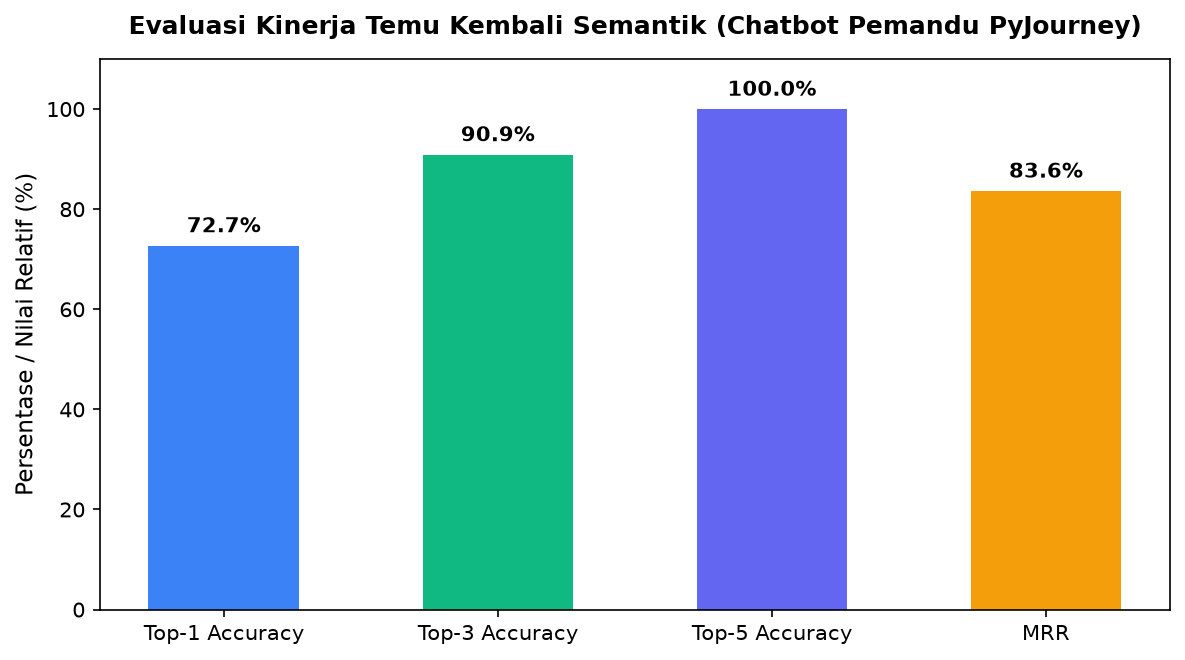

In [14]:
def evaluate_retrieval(eval_df: pd.DataFrame, top_k_max: int = 5) -> dict:
    """
    Menghitung Top-1, Top-3, Top-5 Accuracy dan Mean Reciprocal Rank (MRR)
    berdasarkan kecocokan bab target.
    """
    top1_hits = 0
    top3_hits = 0
    top5_hits = 0
    reciprocal_ranks = []

    evaluation_log = []

    for _, row in eval_df.iterrows():
        q = row["query"]
        target = row["target_slug"]

        ranked_docs = search_corpus(q, top_k=top_k_max)
        retrieved_slugs = [d["chapter_slug"] for d in ranked_docs]

        # Cek peringkat target
        rank = None
        for idx, slug in enumerate(retrieved_slugs):
            if slug == target:
                rank = idx + 1
                break

        if rank is not None:
            reciprocal_ranks.append(1.0 / rank)
            if rank <= 1:
                top1_hits += 1
            if rank <= 3:
                top3_hits += 1
            if rank <= 5:
                top5_hits += 1
        else:
            reciprocal_ranks.append(0.0)

        evaluation_log.append({
            "query": q,
            "target": target,
            "top1_pred": retrieved_slugs[0] if retrieved_slugs else None,
            "top1_correct": rank == 1,
            "rank": rank
        })

    num_samples = len(eval_df)
    metrics = {
        "top1_accuracy": top1_hits / num_samples,
        "top3_accuracy": top3_hits / num_samples,
        "top5_accuracy": top5_hits / num_samples,
        "mrr": np.mean(reciprocal_ranks),
        "log": pd.DataFrame(evaluation_log)
    }
    return metrics

# Jalankan evaluasi pada Test Set (Data Uji Unseen)
test_metrics = evaluate_retrieval(test_df)

print("=" * 50)
print("📊 HASIL EVALUASI ILMIAH PADA DATA UJI (TEST SET):")
print(f"- Top-1 Accuracy : {test_metrics['top1_accuracy'] * 100:.2f}%")
print(f"- Top-3 Accuracy : {test_metrics['top3_accuracy'] * 100:.2f}%")
print(f"- Top-5 Accuracy : {test_metrics['top5_accuracy'] * 100:.2f}%")
print(f"- MRR Score      : {test_metrics['mrr']:.4f}")
print("=" * 50)

# Visualisasi Grafik Evaluasi untuk Bab 4 Skripsi
metric_names = ["Top-1 Accuracy", "Top-3 Accuracy", "Top-5 Accuracy", "MRR"]
metric_values = [
    test_metrics["top1_accuracy"] * 100,
    test_metrics["top3_accuracy"] * 100,
    test_metrics["top5_accuracy"] * 100,
    test_metrics["mrr"] * 100
]

plt.figure(figsize=(8, 4.5), dpi=150)
colors = ["#3b82f6", "#10b981", "#6366f1", "#f59e0b"]
bars = plt.bar(metric_names, metric_values, color=colors, width=0.55)
plt.ylim(0, 110)
plt.ylabel("Persentase / Nilai Relatif (%)", fontsize=11)
plt.title("Evaluasi Kinerja Temu Kembali Semantik (Chatbot Pemandu PyJourney)", fontsize=12, fontweight="bold", pad=12)

for bar in bars:
    height = bar.get_height()
    plt.annotate(f"{height:.1f}%",
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 4), textcoords="offset points",
                 ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plot_path = OUTPUT_DIR / "grafik_evaluasi_chatbot.png"
plt.savefig(plot_path)
print(f"[STATUS] Grafik evaluasi berhasil disimpan ke: {plot_path}")
plt.show()

## 9. Serialisasi & Ekspor Model Artifact untuk Backend / IoT
Tahap akhir dari alur machine learning adalah mengekspor artefak hasil pelatihan/indeksasi:
1. `corpus_metadata.json`: Metadata dokumen yang memetakan indeks vektor ke judul bab, episode, konsep, dan URL rujukan.
2. `corpus_embeddings.npy`: Matriks biner representasi vektor padat ($N \times 384$).

Dengan memisahkan artefak ini, server backend FastAPI (`computer-vision/server.py`) dapat memuat (*load*) basis pengetahuan secara instan tanpa perlu memproses ulang data HTML dari awal.

In [15]:
# 1. Ekspor korpus metadata ke JSON
metadata_file = OUTPUT_DIR / "corpus_metadata.json"
corpus_export_list = df_corpus.to_dict(orient="records")
with open(metadata_file, "w", encoding="utf-8") as f:
    json.dump(corpus_export_list, f, indent=2, ensure_ascii=False)

# 2. Ekspor matriks vektor embedding ke format biner NumPy (.npy)
embeddings_file = OUTPUT_DIR / "corpus_embeddings.npy"
np.save(embeddings_file, corpus_embeddings.cpu().numpy())

print("=== ARTEFAK MODEL BERHASIL DIEKSPOR ===")
print(f"1. Metadata Dokumen  : {metadata_file} ({len(corpus_export_list)} passages)")
print(f"2. Matriks Embedding : {embeddings_file} ({corpus_embeddings.shape})")
print("\n[SELESAI] Model siap diintegrasikan dengan modul FastAPI dan ESP32 Physical Companion!")

=== ARTEFAK MODEL BERHASIL DIEKSPOR ===
1. Metadata Dokumen  : /media/pratama/Data1/Other/SELURUH FILE PERKULIAHAN/SKRIPSI/projek2/training-model/train/output_artifacts/corpus_metadata.json (303 passages)
2. Matriks Embedding : /media/pratama/Data1/Other/SELURUH FILE PERKULIAHAN/SKRIPSI/projek2/training-model/train/output_artifacts/corpus_embeddings.npy (torch.Size([303, 384]))

[SELESAI] Model siap diintegrasikan dengan modul FastAPI dan ESP32 Physical Companion!
